# Titanic Passenger Data | Machine Learning Preprocessing

**Codveda Technologies — Machine Learning Internship**  
**Level 1 | Task 1: Data Preprocessing**

## Project Overview

This project develops a reproducible preprocessing workflow to transform raw Titanic passenger data into a structured, model-ready dataset. The workflow addresses missing values, categorical encoding, feature scaling, and data splitting while preventing data leakage.

## Objectives

- Assess dataset structure, quality, and missing values.
- Select relevant numerical and categorical features.
- Handle missing values using appropriate imputation strategies.
- Encode categorical variables and standardize numerical features.
- Split the dataset into training and held-out validation sets.
- Build and validate a reusable preprocessing pipeline.
- Export processed datasets and the fitted preprocessing pipeline.

## Dataset & Tools

**Dataset:** Titanic — Machine Learning from Disaster (Kaggle)  
**Tools:** Python, pandas, scikit-learn, Matplotlib, Seaborn, joblib

**Data Splitting:** The labeled Kaggle training dataset is divided into an 80% training set and a 20% held-out validation set. This fulfills the task's train/test splitting requirement, as Kaggle's separate competition test file does not include survival labels.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from joblib import dump, load
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TEST_SIZE = 0.20


In [2]:
candidate_paths = [
    Path("/kaggle/input/competitions/titanic/train.csv"),
    Path("/kaggle/input/titanic/train.csv"),
    Path("train.csv")
]

DATA_PATH = next(
    (path for path in candidate_paths if path.is_file()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Titanic train.csv not found. Please provide the dataset."
    )

df = pd.read_csv(DATA_PATH)

print(f"Dataset Source: {DATA_PATH}")
print(f"Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

display(df.head())


Dataset Source: /kaggle/input/competitions/titanic/train.csv
Dataset Shape: 891 rows × 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage (%)": (df.isna().mean() * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(by="Missing Percentage (%)", ascending=False)

display(missing_summary)

,Missing Count,Missing Percentage (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


In [5]:
duplicate_rows = df.duplicated().sum()
duplicate_ids = df["PassengerId"].duplicated().sum()

print(f"Duplicate Rows: {duplicate_rows}")
print(f"Duplicate Passenger IDs: {duplicate_ids}")

Duplicate Rows: 0
Duplicate Passenger IDs: 0


In [6]:
display(df.describe().round(2))

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [7]:
categorical_features = ["Sex", "Embarked", "Pclass"]

for feature in categorical_features:
    print(f"\n{feature}")
    display(
        df[feature]
        .value_counts(dropna=False)
        .rename_axis(feature)
        .to_frame("Count")
    )


Sex


,Count
Sex,
male,577
female,314



Embarked


,Count
Embarked,
S,644
C,168
Q,77
NaN,2



Pclass


,Count
Pclass,
3,491
1,216
2,184


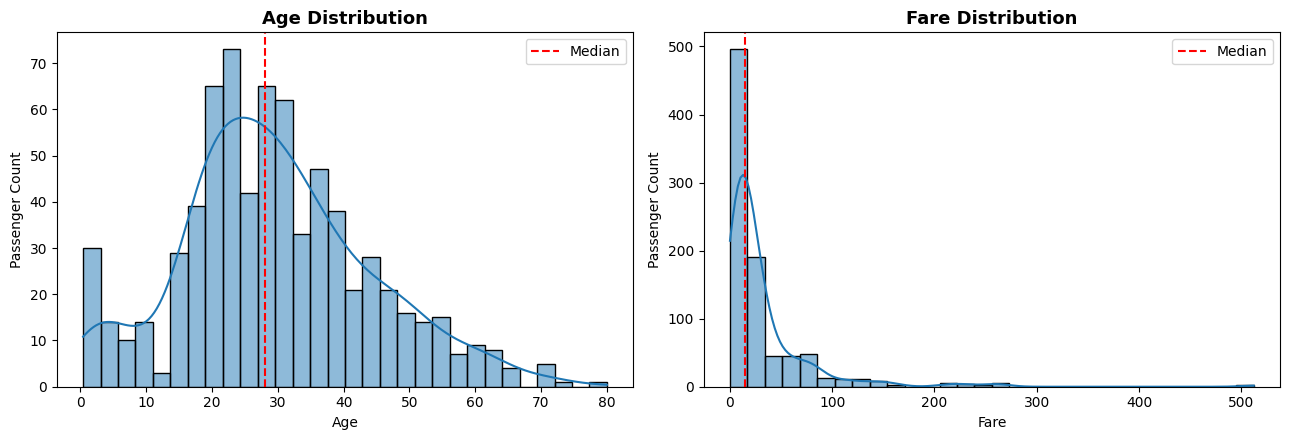

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, feature in zip(axes, ["Age", "Fare"]):
    sns.histplot(data=df, x=feature, bins=30, kde=True, ax=ax)
    ax.axvline(df[feature].median(), color="red", linestyle="--", label="Median")
    ax.set_title(f"{feature} Distribution", fontsize=13, fontweight="bold")
    ax.set_xlabel(feature)
    ax.set_ylabel("Passenger Count")
    ax.legend()

plt.tight_layout()
plt.show()

### Key Findings from Numerical Distributions

- **Age:** Most passengers are concentrated between 20 and 40 years old. The mean (29.70) and median (28.00) are relatively close, indicating only moderate asymmetry.
- **Fare:** The distribution is strongly right-skewed, with a median of 14.45 compared to a mean of 32.20. A small number of passengers paid substantially higher fares.
- **Preprocessing implications:** Median imputation is a reasonable initial choice for missing numerical values. Feature scaling will be applied using statistics learned exclusively from the training set.

High fare values will be retained unless further analysis identifies a valid reason to exclude them.

### Feature Selection Rationale

I selected seven passenger attributes that provide a practical combination of numerical and categorical features for preprocessing.

`PassengerId` was excluded because it serves as a record identifier rather than a meaningful passenger characteristic. `Name` and `Ticket` were excluded because extracting useful information from them would require additional feature engineering.

Although `Cabin` may contain useful information about passenger location, its high missing-value rate (77.10%) requires further investigation. I excluded it from the initial feature set to keep the preprocessing workflow focused and interpretable.

These selections define a baseline feature set for this preprocessing task. They do not imply that the excluded columns have no predictive value.

In [9]:
target_column = "Survived"

numerical_features = ["Age", "SibSp", "Parch", "Fare"]
feature_columns = numerical_features + categorical_features

X = df[feature_columns].copy()
y = df[target_column].copy()

print(f"Selected Features: {len(feature_columns)}")
print(f"Feature Matrix Shape: {X.shape}")
print(f"Target Shape: {y.shape}")

display(X.head())


Selected Features: 7
Feature Matrix Shape: (891, 7)
Target Shape: (891,)


,Age,SibSp,Parch,Fare,Sex,Embarked,Pclass
0,22.0,1,0,7.2500,male,S,3
1,38.0,1,0,71.2833,female,C,1
2,26.0,0,0,7.9250,female,S,3
3,35.0,1,0,53.1000,female,S,1
4,35.0,0,0,8.0500,male,S,3


In [10]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training Set: {X_train.shape[0]} rows")
print(f"Validation Set: {X_val.shape[0]} rows")
print(f"Training Survival Rate: {y_train.mean():.2%}")
print(f"Validation Survival Rate: {y_val.mean():.2%}")


Training Set: 712 rows
Validation Set: 179 rows
Training Survival Rate: 38.34%
Validation Survival Rate: 38.55%


In [11]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [12]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_val_processed = pd.DataFrame(
    X_val_processed,
    columns=feature_names,
    index=X_val.index
)

print(f"Processed Training Shape: {X_train_processed.shape}")
print(f"Processed Validation Shape: {X_val_processed.shape}")

display(X_train_processed.head())


Processed Training Shape: (712, 12)
Processed Validation Shape: (179, 12)


,num__Age,num__SibSp,num__Parch,num__Fare,cat__Sex_female,cat__Sex_male,cat__Embarked_C,cat__Embarked_Q,cat__Embarked_S,cat__Pclass_1,cat__Pclass_2,cat__Pclass_3
692,-0.081135,-0.465084,-0.466183,0.513812,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
481,-0.081135,-0.465084,-0.466183,-0.662563,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
527,-0.081135,-0.465084,-0.466183,3.955399,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
855,-0.887827,-0.465084,0.727782,-0.467874,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
801,0.110934,0.478335,0.727782,-0.115977,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [13]:
validation_checks = {
    "Training rows preserved": len(X_train_processed) == len(X_train),
    "Validation rows preserved": len(X_val_processed) == len(X_val),
    "Consistent feature columns": X_train_processed.columns.equals(X_val_processed.columns),
    "No missing training values": not X_train_processed.isna().any().any(),
    "No missing validation values": not X_val_processed.isna().any().any(),
    "All features are numeric": all(
        pd.api.types.is_numeric_dtype(dtype)
        for dtype in X_train_processed.dtypes
    ),
    "Target excluded from features": target_column not in X_train_processed.columns,
    "Original row indices preserved": (
        X_train_processed.index.equals(X_train.index)
        and X_val_processed.index.equals(X_val.index)
    )
}

validation_results = pd.DataFrame({
    "Validation Check": validation_checks.keys(),
    "Status": ["PASS" if result else "FAIL" for result in validation_checks.values()]
})

display(validation_results)

assert all(validation_checks.values()), "Preprocessing validation failed."


,Validation Check,Status
0,Training rows preserved,PASS
1,Validation rows preserved,PASS
2,Consistent feature columns,PASS
3,No missing training values,PASS
4,No missing validation values,PASS
5,All features are numeric,PASS
6,Target excluded from features,PASS
7,Original row indices preserved,PASS


In [14]:
fitted_numerical_pipeline = preprocessor.named_transformers_["num"]

imputation_values = fitted_numerical_pipeline.named_steps["imputer"].statistics_

transformation_audit = pd.DataFrame({
    "Feature": numerical_features,
    "Missing (Train)": X_train[numerical_features].isna().sum().values,
    "Missing (Validation)": X_val[numerical_features].isna().sum().values,
    "Imputation Value": imputation_values,
    "Scaled Train Mean": [
        X_train_processed[f"num__{feature}"].mean()
        for feature in numerical_features
    ],
    "Scaled Train Std": [
        X_train_processed[f"num__{feature}"].std(ddof=0)
        for feature in numerical_features
    ]
})

display(transformation_audit.round(3))


,Feature,Missing (Train),Missing (Validation),Imputation Value,Scaled Train Mean,Scaled Train Std
0,Age,137,40,28.500,0.0,1.0
1,SibSp,0,0,0.000,-0.0,1.0
2,Parch,0,0,0.000,-0.0,1.0
3,Fare,0,0,14.454,-0.0,1.0


In [15]:
fitted_categorical_pipeline = preprocessor.named_transformers_["cat"]

categorical_audit = pd.DataFrame({
    "Feature": categorical_features,
    "Missing (Train)": X_train[categorical_features].isna().sum().values,
    "Missing (Validation)": X_val[categorical_features].isna().sum().values,
    "Imputation Value": fitted_categorical_pipeline.named_steps["imputer"].statistics_,
    "Encoded Categories": [
        ", ".join(map(str, categories))
        for categories in fitted_categorical_pipeline.named_steps["encoder"].categories_
    ]
})

display(categorical_audit)


,Feature,Missing (Train),Missing (Validation),Imputation Value,Encoded Categories
0,Sex,0,0,male,"female, male"
1,Embarked,2,0,S,"C, Q, S"
2,Pclass,0,0,3,"1, 2, 3"


In [16]:
OUTPUT_ROOT = (
    Path("/kaggle/working")
    if Path("/kaggle/working").is_dir()
    else Path("outputs")
)

OUTPUT_DIR = OUTPUT_ROOT / "titanic_preprocessing"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_output = X_train_processed.assign(Survived=y_train)
validation_output = X_val_processed.assign(Survived=y_val)

train_output.to_csv(OUTPUT_DIR / "train_processed.csv", index=False)
validation_output.to_csv(OUTPUT_DIR / "validation_processed.csv", index=False)

dump(preprocessor, OUTPUT_DIR / "preprocessor.joblib")

print(f"Output Directory: {OUTPUT_DIR}")

for file_path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{file_path.name} — {file_path.stat().st_size / 1024:.2f} KB")

Output Directory: /kaggle/working/titanic_preprocessing
preprocessor.joblib — 3.90 KB
train_processed.csv — 80.03 KB
validation_processed.csv — 20.25 KB


In [17]:
saved_train = pd.read_csv(OUTPUT_DIR / "train_processed.csv")
saved_validation = pd.read_csv(OUTPUT_DIR / "validation_processed.csv")
saved_preprocessor = load(OUTPUT_DIR / "preprocessor.joblib")

expected_columns = [*feature_names, target_column]

assert saved_train.shape == (len(X_train), len(expected_columns))
assert saved_validation.shape == (len(X_val), len(expected_columns))

assert saved_train.columns.tolist() == expected_columns
assert saved_validation.columns.tolist() == expected_columns

assert not saved_train.isna().any().any()
assert not saved_validation.isna().any().any()

assert saved_train[target_column].tolist() == y_train.tolist()
assert saved_validation[target_column].tolist() == y_val.tolist()

assert saved_preprocessor.get_feature_names_out().tolist() == feature_names.tolist()
assert saved_preprocessor.transform(X_val.iloc[:1]).shape == (1, len(feature_names))

print("All exported artifacts passed integrity checks.")


All exported artifacts passed integrity checks.


## Results & Conclusion

### Preprocessing Results

I developed a reproducible preprocessing pipeline to prepare the Titanic passenger dataset for machine learning.

| Metric | Result |
|---|---|
| Original Dataset | 891 rows, 12 columns |
| Selected Features | 7 |
| Training Set | 712 samples |
| Validation Set | 179 samples |
| Features After Encoding | 12 |
| Missing Values After Processing | 0 |
| Validation Checks | All Passed |

### Key Outcomes

- Handled missing values using median and most-frequent imputation.
- Encoded categorical features and standardized numerical features.
- Preserved the target distribution through stratified data splitting.
- Prevented data leakage by fitting preprocessing transformations exclusively on the training set.
- Verified the consistency and integrity of the processed datasets.
- Exported the transformed datasets and fitted preprocessing pipeline for reuse.

### Conclusion

The preprocessing workflow successfully transformed the selected passenger attributes into consistent, numerical, model-ready features.

The final outputs passed the implemented validation and artifact integrity checks. Model training and predictive performance evaluation are outside the scope of this task.
